# Marine heatwaves vs Algarve octopus catch per unit effort

Reproduces the analysis of marine heatwave (MHW) days near **Vila Real de Santo António** against *Octopus vulgaris* catch per unit effort (CPUE) in the Algarve.

**Inputs**
- `MHW_FILE`: monthly MHW metrics per grid cell (columns `lat, lon, year, month, mhw_days, intensity_cum, intensity_max, ...`; longitude 0–360)
- `CATCH_FILE`: CatDyn output with `Year`, `Period.month`, `Observed.Catch.kg`, `Effort.NDays`, ...

**Main test:** each calendar month's MHW days against CPUE in the following **August–July fishing season** (Spearman ρ, permutation p-values, Benjamini–Hochberg and Bonferroni correction for 12 months).

## 1. Settings

In [1]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

import os, glob
FOLDER     = '/Users/miguelsilveira/Documents/GitHub/marineheatwaves/Octopus_VRSA'
MHW_FILE   = os.path.join(FOLDER, 'vrsa_mhw_grid.csv')                 # MHW grid file
CATCH_FILE = glob.glob(os.path.join(FOLDER, '*ovulgaris*.xlsx'))[0]    # octopus CatDyn file
print(MHW_FILE, os.path.exists(MHW_FILE))
print(CATCH_FILE, os.path.exists(CATCH_FILE))

SITE_NAME = 'Vila Real de Santo António'
SITE_LAT, SITE_LON = 37.194, -7.416           # degrees, longitude in -180..180
N_CELLS = 1                                   # number of nearest grid cells to average

SEASON_START = 8          # fishing season runs Aug (8) to Jul of the next year
N_PERM = 20000            # permutations for p-values
SEED = 42

# Optional manual changes to monthly MHW days, e.g. {(2010, 6): 0}. Empty = raw data.
MHW_CORRECTIONS = {}

/Users/miguelsilveira/Documents/GitHub/marineheatwaves/Octopus_VRSA/vrsa_mhw_grid.csv True
/Users/miguelsilveira/Documents/GitHub/marineheatwaves/Octopus_VRSA/ovulgaris.algarve.preds.xlsx True


## 2. Load data and pick the nearest grid cell(s)

In [2]:
mhw = pd.read_csv(MHW_FILE)
octo = pd.read_excel(CATCH_FILE)
octo['month'] = (octo['Period.month'] - 1) % 12 + 1

cells = mhw.groupby(['lat', 'lon']).size().reset_index()[['lat', 'lon']]
lon360 = SITE_LON % 360
cells['dist_km'] = np.hypot((cells.lat - SITE_LAT) * 111.2,
                            (cells.lon - lon360) * 111.2 * np.cos(np.radians(SITE_LAT)))
cells = cells.sort_values('dist_km')
use = cells.head(N_CELLS)
print(f'Nearest cells to {SITE_NAME}:')
display(cells.head(4).assign(lon_deg=lambda d: d.lon - 360).round(3))

sel = mhw.merge(use[['lat', 'lon']], on=['lat', 'lon'])
m = sel.groupby(['year', 'month'], as_index=False)[['mhw_days', 'intensity_cum', 'intensity_max']].mean()
for (y, mo), v in MHW_CORRECTIONS.items():
    m.loc[(m.year == y) & (m.month == mo), 'mhw_days'] = v
print('Octopus data:', octo.Year.min(), '-', octo.Year.max(), f'({len(octo)} months)')

Nearest cells to Vila Real de Santo António:


,lat,lon,dist_km,lon_deg
0,37.125,352.375,20.04,-7.625


Octopus data: 2006 - 2020 (180 months)


## 3. Build fishing seasons (August–July) and CPUE

In [3]:
octo['season'] = np.where(octo.month >= SEASON_START, octo.Year, octo.Year - 1)
seas = (octo.groupby('season')
            .agg(catch_kg=('Observed.Catch.kg', 'sum'),
                 effort_days=('Effort.NDays', 'sum'),
                 n_months=('month', 'size')))
seas = seas[seas.n_months == 12].copy()          # keep complete seasons only
seas['cpue'] = seas.catch_kg / seas.effort_days
seas.index.name = 'season_start_year'
seas.round(1)

,catch_kg,effort_days,n_months,cpue
season_start_year,,,,
2006,1289272.3,33990,12,37.9
2007,5367499.9,60232,12,89.1
2008,2124910.7,42383,12,50.1
2009,2702438.3,38196,12,70.8
2010,1342982.0,29959,12,44.8
2011,1142186.6,26740,12,42.7
2012,3795458.4,37684,12,100.7
2013,2378018.2,34742,12,68.4
2014,2557355.3,38203,12,66.9


## 4. Helper functions

In [4]:
rng = np.random.default_rng(SEED)

def perm_p(x, y, n=N_PERM):
    r0 = stats.spearmanr(x, y)[0]
    perm = np.array([stats.spearmanr(rng.permutation(x), y)[0] for _ in range(n)])
    return r0, (np.sum(np.abs(perm) >= abs(r0)) + 1) / (n + 1)

def bh(p):
    p = np.asarray(p); n = len(p); o = np.argsort(p)
    q = p[o] * n / np.arange(1, n + 1)
    q = np.minimum.accumulate(q[::-1])[::-1]
    out = np.empty(n); out[o] = np.minimum(q, 1); return out

def month_vs_next_season(mo):
    """MHW days in calendar month `mo` vs CPUE of the next complete Aug-Jul season.
    Jan-Jul -> season starting that August; Aug-Dec -> season starting the next August."""
    h = m[m.month == mo].set_index('year').mhw_days.copy()
    h.index = h.index + (0 if mo < SEASON_START else 1)
    return h.rename('mhw_days').to_frame().join(seas, how='inner')

## 5. Every month vs CPUE in the following season

In [5]:
rows = []
for mo in range(1, 13):
    J = month_vs_next_season(mo)
    rho, pp = perm_p(J.mhw_days.values, J.cpue.values)
    rho_c, p_c = stats.spearmanr(J.mhw_days, J.catch_kg)
    rows.append(dict(month=mo, n_seasons=len(J), years_with_mhw=int((J.mhw_days > 0).sum()),
                     rho_cpue=rho, perm_p=pp, rho_catch=rho_c, p_catch=p_c,
                     cpue_after_mhw=J.cpue[J.mhw_days > 0].mean(),
                     cpue_no_mhw=J.cpue[J.mhw_days == 0].mean()))
res = pd.DataFrame(rows)
res['q_BH'] = bh(res.perm_p)
res['p_bonferroni'] = np.minimum(res.perm_p * 12, 1)
res.round(3)

,month,n_seasons,years_with_mhw,rho_cpue,perm_p,rho_catch,p_catch,cpue_after_mhw,cpue_no_mhw,q_BH,p_bonferroni
0,1,14,5,-0.156,0.597,-0.090,0.761,56.182,62.114,0.854,1.000
1,2,14,3,-0.223,0.452,-0.205,0.482,52.124,62.142,0.774,1.000
2,3,14,1,-0.172,0.712,-0.034,0.907,50.136,60.754,0.854,1.000
3,4,14,3,-0.242,0.418,-0.327,0.253,51.997,62.177,0.774,1.000
4,5,14,7,-0.251,0.380,-0.359,0.207,58.462,61.529,0.774,1.000
5,6,14,6,-0.845,0.000,-0.837,0.000,43.533,72.343,0.002,0.002
6,7,14,5,-0.499,0.073,-0.484,0.079,47.826,66.756,0.436,0.872
7,8,14,6,-0.338,0.242,-0.304,0.290,56.526,62.597,0.774,1.000
8,9,14,7,-0.007,0.987,-0.049,0.867,63.153,56.838,0.987,1.000
9,10,14,5,0.310,0.282,0.284,0.325,67.836,55.639,0.774,1.000


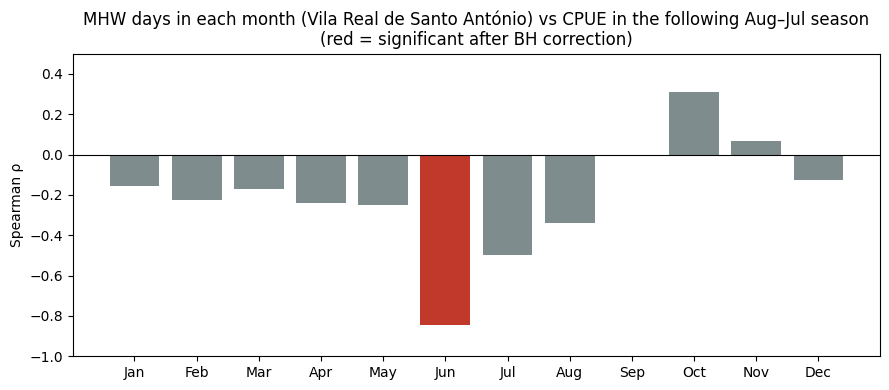

In [6]:
names = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
fig, ax = plt.subplots(figsize=(9, 4))
cols = ['#c0392b' if q < 0.05 else '#7f8c8d' for q in res.q_BH]
ax.bar(names, res.rho_cpue, color=cols)
ax.axhline(0, color='k', lw=0.8)
ax.set_ylabel('Spearman ρ'); ax.set_ylim(-1, 0.5)
ax.set_title(f'MHW days in each month ({SITE_NAME}) vs CPUE in the following Aug–Jul season\n(red = significant after BH correction)')
plt.tight_layout(); plt.show()

## 5b. Every month vs CPUE in the same month

In [7]:
octo['cpue'] = octo['Observed.Catch.kg'] / octo['Effort.NDays']
d = octo.merge(m[['year', 'month', 'mhw_days']], left_on=['Year', 'month'], right_on=['year', 'month'])
rows = []
for mo in range(1, 13):
    s = d[d.month == mo]
    row = dict(month=mo, n_years=len(s), years_with_mhw=int((s.mhw_days > 0).sum()))
    if s.mhw_days.nunique() > 1:
        rho, pp = perm_p(s.mhw_days.values, s.cpue.values)
        row.update(rho_cpue=rho, perm_p=pp,
                   cpue_mhw=s.cpue[s.mhw_days > 0].mean(), cpue_no_mhw=s.cpue[s.mhw_days == 0].mean())
    rows.append(row)
same = pd.DataFrame(rows)
ok = same.perm_p.notna()
same.loc[ok, 'q_BH'] = bh(same.loc[ok, 'perm_p'])
same.round(3)

,month,n_years,years_with_mhw,rho_cpue,perm_p,cpue_mhw,cpue_no_mhw,q_BH
0,1,15,5,0.123,0.658,75.893,64.942,0.979
1,2,15,4,0.009,0.979,65.807,61.754,0.979
2,3,15,1,0.309,0.399,89.383,58.574,0.979
3,4,15,4,0.312,0.260,74.692,54.674,0.979
4,5,15,8,0.218,0.430,60.032,48.117,0.979
5,6,15,7,0.050,0.857,53.846,53.608,0.979
6,7,15,6,0.028,0.927,54.625,55.716,0.979
7,8,15,6,0.133,0.637,58.263,52.484,0.979
8,9,15,8,0.301,0.271,53.449,47.451,0.979
9,10,15,5,-0.055,0.845,58.154,55.901,0.979


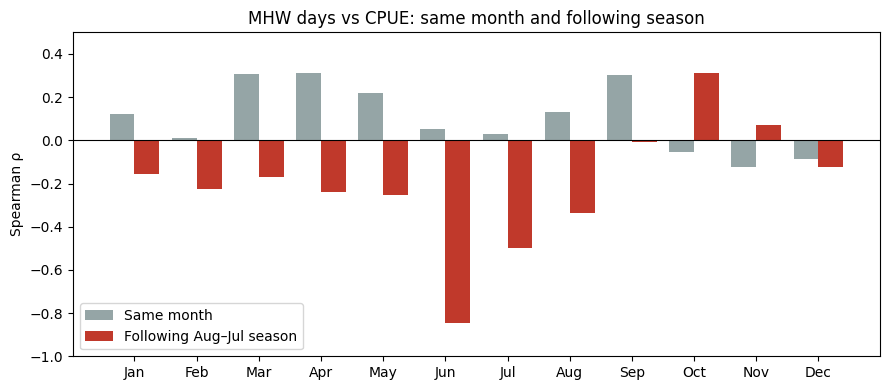

In [8]:
fig, ax = plt.subplots(figsize=(9, 4))
w = 0.4; x = np.arange(12)
ax.bar(x - w/2, same.rho_cpue, w, label='Same month', color='#95a5a6')
ax.bar(x + w/2, res.rho_cpue, w, label='Following Aug–Jul season', color='#c0392b')
ax.set_xticks(x, names); ax.axhline(0, color='k', lw=0.8); ax.set_ylim(-1, 0.5)
ax.set_ylabel('Spearman ρ'); ax.legend()
ax.set_title('MHW days vs CPUE: same month and following season')
plt.tight_layout(); plt.show()

## 6. June, July and June + July in detail

In [9]:
H = pd.DataFrame({'jun': m[m.month == 6].set_index('year').mhw_days,
                  'jul': m[m.month == 7].set_index('year').mhw_days})
H['jun_jul'] = H.jun + H.jul
J = H.join(seas, how='inner')

out = []
for x in ['jun', 'jul', 'jun_jul']:
    rho, pp = perm_p(J[x].values, J.cpue.values)
    a, b = J.cpue[J[x] > 0], J.cpue[J[x] == 0]
    out.append(dict(window=x, rho_cpue=rho, perm_p=pp,
                    cpue_after_mhw=a.mean(), n_mhw=len(a),
                    cpue_no_mhw=b.mean(), n_none=len(b),
                    mannwhitney_p=stats.mannwhitneyu(a, b).pvalue))
pd.DataFrame(out).round(4)

,window,rho_cpue,perm_p,cpue_after_mhw,n_mhw,cpue_no_mhw,n_none,mannwhitney_p
0,jun,-0.8446,0.0003,43.5326,6,72.3425,8,0.0007
1,jul,-0.4995,0.0700,47.8261,5,66.7561,9,0.0599
2,jun_jul,-0.8332,0.0005,46.3882,7,73.6026,7,0.0023


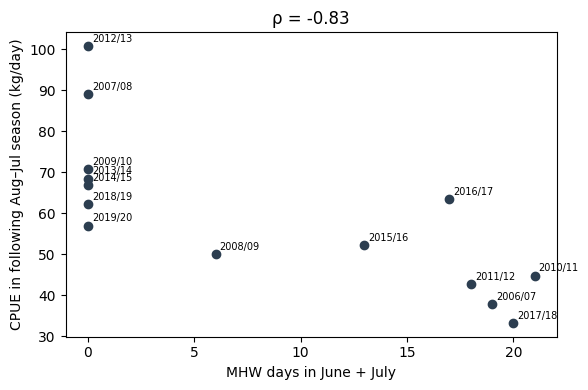

In [10]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(J.jun_jul, J.cpue, color='#2c3e50')
for yr, r in J.iterrows():
    ax.annotate(f'{yr}/{str(yr+1)[2:]}', (r.jun_jul, r.cpue), fontsize=7, xytext=(3, 3), textcoords='offset points')
ax.set_xlabel('MHW days in June + July'); ax.set_ylabel('CPUE in following Aug–Jul season (kg/day)')
ax.set_title(f'ρ = {stats.spearmanr(J.jun_jul, J.cpue)[0]:.2f}')
plt.tight_layout(); plt.show()

## 7. Robustness of the June result

In [11]:
Jn = month_vs_next_season(6)
# drop-one-year
jk = {y: stats.spearmanr(Jn.drop(y).mhw_days, Jn.drop(y).cpue)[0] for y in Jn.index}
print('Drop-one-year rho range: %.2f to %.2f' % (min(jk.values()), max(jk.values())))
# bootstrap 95% interval
bs = []
for _ in range(5000):
    i = rng.integers(0, len(Jn), len(Jn))
    x = Jn.mhw_days.values[i]
    if x.std() > 0:
        bs.append(stats.spearmanr(x, Jn.cpue.values[i])[0])
print('Bootstrap 95%% interval: %.2f to %.2f' % tuple(np.percentile(bs, [2.5, 97.5])))
# timing: June MHW vs CPUE in windows of the same and next year
def window_cpue(months, shift):
    s = octo[octo.month.isin(months)].groupby('Year').agg(c=('Observed.Catch.kg', 'sum'), e=('Effort.NDays', 'sum'))
    s.index = s.index - shift
    return s.c / s.e
jun = m[m.month == 6].set_index('year').mhw_days
for lab, months, sh in [('same Jan-May (before)', range(1, 6), 0), ('same Jul-Sep', range(7, 10), 0),
                        ('same Oct-Dec', range(10, 13), 0), ('next Jan-Jul', range(1, 8), 1)]:
    K = pd.concat([jun.rename('x'), window_cpue(list(months), sh).rename('y')], axis=1, join='inner')
    print(f'{lab:24s} rho = %.2f  p = %.3f' % stats.spearmanr(K.x, K.y))

Drop-one-year rho range: -0.86 to -0.80
Bootstrap 95% interval: -0.93 to -0.61
same Jan-May (before)    rho = 0.25  p = 0.369
same Jul-Sep             rho = -0.51  p = 0.055
same Oct-Dec             rho = -0.66  p = 0.007
next Jan-Jul             rho = -0.83  p = 0.000


## 8. Save results

In [12]:
with pd.ExcelWriter('mhw_octopus_every_month.xlsx') as w:
    res.to_excel(w, 'every_month', index=False)
    same.to_excel(w, 'same_month', index=False)
    pd.DataFrame(out).to_excel(w, 'june_july', index=False)
    seas.to_excel(w, 'seasons')
    m.to_excel(w, 'mhw_monthly', index=False)
print('Saved mhw_octopus_every_month.xlsx')

Saved mhw_octopus_every_month.xlsx


/var/folders/wq/98_by44j0113pwx7jtjgd74w0000gn/T/ipykernel_32699/1770186645.py:2: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  res.to_excel(w, 'every_month', index=False)
/var/folders/wq/98_by44j0113pwx7jtjgd74w0000gn/T/ipykernel_32699/1770186645.py:3: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  same.to_excel(w, 'same_month', index=False)
/var/folders/wq/98_by44j0113pwx7jtjgd74w0000gn/T/ipykernel_32699/1770186645.py:4: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  pd.DataFrame(out).to_excel(w, 'june_july', index=False)
/var/folders/wq/98_by44j0113pwx7jtjgd74w0000gn/T/ipykernel_32699/1770186645.py:5: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will

## Notes
- Monthly MHW totals split events at month boundaries; daily event data would allow event-based exposure windows (for example any heatwave overlapping 15 May–31 July).
- Rainfall, a published driver of Algarve octopus catch, is not included.
- The June window was identified by exploring the data; confirm with seasons after 2020.